In [19]:
import sys
import csv
import requests
import shutil
import zipfile
import hashlib
import pandas as pd
from io import BytesIO
from PIL import Image as PILImage
from pathlib import Path
from datasets import load_dataset, Image as HFImage
from collections import Counter

print("Libraries imported successfully.")

Libraries imported successfully.


In [ ]:
# from datasets import load_dataset

# dataset = load_dataset(
#     "AIOmarRehan/Vehicles",
#     split="train",
#     streaming=True
# )

# print("Dataset loaded successfully!")

d:\Pinterest-AI-Recommender\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
d:\Pinterest-AI-Recommender\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\musam\.cache\huggingface\hub\datasets--AIOmarRehan--Vehicles. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate develop

Dataset loaded successfully!


Dataset columns: dict_keys(['image', 'label'])
Image column: image
Image size: (140, 140)


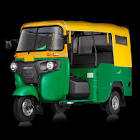

label : 0


In [ ]:
# from PIL import Image
# from IPython.display import display
# from io import BytesIO

# # Dataset se ek sample lena
# sample = next(iter(dataset))

# # Dataset ke columns check karna
# print("Dataset columns:", sample.keys())

# # Image aur baqi information display karna
# for key, value in sample.items():
#     if isinstance(value, Image.Image):
#         print("Image column:", key)
#         print("Image size:", value.size)
#         display(value)

#     elif isinstance(value, dict) and value.get("bytes"):
#         img = Image.open(BytesIO(value["bytes"]))
#         print("Image column:", key)
#         print("Image size:", img.size)
#         display(img)

#     else:
#         print(key, ":", value)

In [6]:
print("Dataset features:")
print(dataset.features)

print("\nFirst sample details:")
sample = next(iter(dataset))

for key, value in sample.items():
    if key == "image":
        print("Image type:", type(value))
        print("Image size:", value.size)
    else:
        print(f"{key}: {value}")

Dataset features:
{'image': Image(mode=None, decode=True), 'label': ClassLabel(names=['Auto Rickshaws', 'Bikes', 'Cars', 'Motorcycles', 'Planes', 'Ships', 'Trains'])}

First sample details:
Image type: <class 'PIL.JpegImagePlugin.JpegImageFile'>
Image size: (140, 140)
label: 0


In [ ]:
from collections import Counter

label_counts = Counter()

for sample in dataset:
    label_counts[sample["label"]] += 1

label_names = dataset.features["label"].names

print("Images per category:\n")

for label_id, count in sorted(label_counts.items()):
    print(f"{label_names[label_id]}: {count}")

print("\nTotal images:", sum(label_counts.values()))

Images per category:

Auto Rickshaws: 800
Bikes: 800
Cars: 790
Motorcycles: 800
Planes: 800
Ships: 800
Trains: 800

Total images: 5590


VEHICLE IMAGE DATASET

In [ ]:
from pathlib import Path
from datasets import load_dataset
import csv
from collections import Counter


project_root = Path.cwd()
if project_root.name.lower() == "notebooks":
    project_root = project_root.parent

images_dir = project_root / "Data" / "images"
metadata_path = project_root / "Data" / "metadata.csv"
images_dir.mkdir(parents=True, exist_ok=True)

dataset = load_dataset(
    "AIOmarRehan/Vehicles",
    split="train",
    streaming=True
)

label_names = dataset.features["label"].names
category_counts = {name: 0 for name in label_names}
total = 0

with open(metadata_path, "w", newline="", encoding="utf-8") as file:
    writer = csv.DictWriter(file, fieldnames=[
        "image_id", "filename", "category", "label",
        "source_dataset", "source_url", "license"
    ])
    writer.writeheader()

    for sample in dataset:
        label = sample["label"]
        category = label_names[label]
        category_counts[category] += 1

        filename = (
            f"{category.lower().replace(' ', '_')}_"
            f"{category_counts[category]:04d}.jpg"
        )

        sample["image"].convert("RGB").save(
            images_dir / filename,
            format="JPEG"
        )

        writer.writerow({
            "image_id": total + 1,
            "filename": filename,
            "category": category,
            "label": label,
            "source_dataset": "AIOmarRehan/Vehicles",
            "source_url": "https://huggingface.co/datasets/AIOmarRehan/Vehicles",
            "license": "CC0-1.0 (verify against dataset card)"
        })
        total += 1

print(f"Total images saved: {total}")
print(f"Images location: {images_dir}")
print(f"Metadata location: {metadata_path}")
print("Category counts:", category_counts)

d:\Pinterest-AI-Recommender\.venv\Lib\site-packages\PIL\Image.py:1136: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Total images saved: 5590
Images location: d:\Pinterest-AI-Recommender\Data\images
Metadata location: d:\Pinterest-AI-Recommender\Data\metadata.csv
Category counts: {'Auto Rickshaws': 800, 'Bikes': 800, 'Cars': 790, 'Motorcycles': 800, 'Planes': 800, 'Ships': 800, 'Trains': 800}


NATURE IMAGE DATASET

In [7]:

from pathlib import Path
from datasets import load_dataset, Image as HFImage
from PIL import Image, UnidentifiedImageError
import csv
import io

root = Path.cwd()
if root.name.lower() == "notebooks":
    root = root.parent

images_dir = root / "Data" / "images"
metadata_path = root / "Data" / "metadata.csv"
images_dir.mkdir(parents=True, exist_ok=True)

dataset = load_dataset("KoalaAI/StockImages-CC0", split="train")
dataset = dataset.cast_column("image", HFImage(decode=False))

nature_words = {
    "nature", "forest", "tree", "mountain", "landscape",
    "lake", "river", "waterfall", "flower", "plant",
    "ocean", "sea", "beach", "wildlife", "wilderness",
    "grass", "garden", "sunset", "sunrise", "desert"
}

with open(metadata_path, newline="", encoding="utf-8") as f:
    reader = csv.DictReader(f)
    rows = list(reader)
    fields = reader.fieldnames

existing_files = {row["filename"] for row in rows}
added = 0
skipped = 0

for sample in dataset:
    tags = sample.get("tags", "")
    if isinstance(tags, list):
        tags = " ".join(map(str, tags))
    tags = set(str(tags).lower().replace(",", " ").split())

    if not tags.intersection(nature_words):
        continue

    try:
        image_info = sample["image"]
        raw_bytes = image_info.get("bytes")

        if raw_bytes:
            image = Image.open(io.BytesIO(raw_bytes))
        else:
            image_path = image_info.get("path")
            if not image_path:
                skipped += 1
                continue
            image = Image.open(image_path)

        image = image.convert("RGB")
        filename = f"nature_stock_{added + 1:04d}.jpg"

        while filename in existing_files:
            added += 1
            filename = f"nature_stock_{added + 1:04d}.jpg"

        image.save(images_dir / filename, format="JPEG")
        existing_files.add(filename)

        rows.append({
            "image_id": len(rows) + 1,
            "filename": filename,
            "category": "Nature",
            "label": "",
            "source_dataset": "KoalaAI/StockImages-CC0",
            "source_url": "https://huggingface.co/datasets/KoalaAI/StockImages-CC0",
            "license": "CC0-1.0 (as listed on dataset card)"
        })
        added += 1

    except (UnidentifiedImageError, OSError, TypeError, ValueError):
        skipped += 1

with open(metadata_path, "w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(f, fieldnames=fields)
    writer.writeheader()
    writer.writerows(rows)

print(f"Nature images added: {added}")
print(f"Unsupported images skipped: {skipped}")
print(f"Total metadata records: {len(rows)}")


Nature images added: 1955
Unsupported images skipped: 0
Total metadata records: 7545


FASHION IMAGE DATASET

In [11]:

root = Path.cwd()
if root.name.lower() == "notebooks":
    root = root.parent

# Find downloaded ZIP
downloads = Path.home() / "Downloads"
zip_files = list(downloads.glob("*clothing-dataset*.zip"))

if not zip_files:
    raise FileNotFoundError(
        "Clothing dataset ZIP Downloads folder mein nahi mili."
    )

zip_path = max(zip_files, key=lambda p: p.stat().st_mtime)

# Extract ZIP locally
extract_dir = root / "Data" / "Fashion_Source"
extract_dir.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as archive:
    archive.extractall(extract_dir)

# Locate CSV and images folder
csv_path = next(extract_dir.rglob("images.csv"))
source_images = csv_path.parent / "images"
images_dir = root / "Data" / "images"
metadata_path = root / "Data" / "metadata.csv"

# Load source and existing metadata
with open(csv_path, newline="", encoding="utf-8") as f:
    clothing_rows = list(csv.DictReader(f))

with open(metadata_path, newline="", encoding="utf-8") as f:
    reader = csv.DictReader(f)
    metadata = list(reader)
    fields = reader.fieldnames

existing = {row["filename"] for row in metadata}
added = 0

for item in clothing_rows:
    image_id = item["image"]
    source = source_images / f"{image_id}.jpg"
    filename = f"fashion_{image_id}.jpg"

    if filename in existing or not source.exists():
        continue

    shutil.copy2(source, images_dir / filename)

    metadata.append({
        "image_id": len(metadata) + 1,
        "filename": filename,
        "category": "Fashion",
        "label": item.get("label", ""),
        "source_dataset": "alexeygrigorev/clothing-dataset",
        "source_url": "https://github.com/alexeygrigorev/clothing-dataset",
        "license": "CC0-1.0 (as listed in repository)"
    })

    existing.add(filename)
    added += 1

with open(metadata_path, "w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(f, fieldnames=fields)
    writer.writeheader()
    writer.writerows(metadata)

print(f"Fashion images added: {added}")
print(f"Total metadata records: {len(metadata)}")
print(f"Images folder: {images_dir}")


Fashion images added: 5398
Total metadata records: 12943
Images folder: d:\Pinterest-AI-Recommender\Data\images


AESTHETIC IMAGE DATASET

In [20]:

# Project paths
BASE = Path.cwd().parent if Path.cwd().name == "Notebooks" else Path.cwd()
DATA = BASE / "Data"
IMAGES = DATA / "images"
CSV = DATA / "metadata.csv"

IMAGES.mkdir(parents=True, exist_ok=True)
df = pd.read_csv(CSV)

# Dataset load: images ko automatic decode na karo
ds = load_dataset("KoalaAI/StockImages-CC0", split="train")
ds = ds.cast_column("image", HFImage(decode=False))

# Aesthetic se relevant tags
keywords = {
    "interior", "living room", "bedroom", "decor", "furniture",
    "cozy", "minimalist", "vintage", "still life", "aesthetic",
    "architecture", "cafe", "coffee shop", "lighting", "texture",
    "abstract", "art", "design", "bokeh", "wall", "shelf"
}

# Existing image hashes, taake duplicate files na add hon
existing_hashes = set()
for file in IMAGES.iterdir():
    if file.is_file():
        try:
            existing_hashes.add(
                hashlib.md5(file.read_bytes()).hexdigest()
            )
        except OSError:
            pass

added = 0
limit = 400
records = []

for i, item in enumerate(ds):
    if added >= limit:
        break

    tags = str(item.get("tags", "")).lower()
    tag_set = {tag.strip() for tag in tags.split(",")}

    if not (tag_set & keywords):
        continue

    image_data = item["image"]
    try:
        if image_data.get("bytes"):
            img = PILImage.open(BytesIO(image_data["bytes"])).convert("RGB")
        elif image_data.get("path"):
            img = PILImage.open(image_data["path"]).convert("RGB")
        else:
            continue

        buffer = BytesIO()
        img.save(buffer, format="JPEG", quality=92)
        image_bytes = buffer.getvalue()
        file_hash = hashlib.md5(image_bytes).hexdigest()

        if file_hash in existing_hashes:
            continue

        filename = f"aesthetic_stock_{i:05d}.jpg"
        (IMAGES / filename).write_bytes(image_bytes)
        existing_hashes.add(file_hash)

        records.append({
            "image_id": f"aesthetic_{i:05d}",
            "filename": filename,
            "category": "Aesthetic",
            "label": ", ".join(sorted(tag_set)),
            "source_dataset": "KoalaAI/StockImages-CC0",
            "source_url": "https://huggingface.co/datasets/KoalaAI/StockImages-CC0",
            "license": "CC0-1.0"
        })
        added += 1

    except Exception:
        continue

if records:
    df = pd.concat([df, pd.DataFrame(records)], ignore_index=True)
    df = df.drop_duplicates(subset="filename")
    df.to_csv(CSV, index=False)

print("Aesthetic images added:", added)
print("Total metadata records:", len(df))
print("Metadata saved:", CSV)


Aesthetic images added: 400
Total metadata records: 13343
Metadata saved: d:\Pinterest-AI-Recommender\Data\metadata.csv


INTERIOR IMAGE DATASET

In [21]:

BASE = Path.cwd().parent if Path.cwd().name == "Notebooks" else Path.cwd()
DATA = BASE / "Data"
IMAGES = DATA / "images"
CSV = DATA / "metadata.csv"

df = pd.read_csv(CSV)

# Existing stock-image dataset load karo
ds = load_dataset("KoalaAI/StockImages-CC0", split="train")
ds = ds.cast_column("image", HFImage(decode=False))

interior_tags = {
    "interior", "living room", "bedroom", "kitchen", "bathroom",
    "furniture", "home decor", "room", "sofa", "chair",
    "table", "interior design", "home", "apartment", "wardrobe"
}

# Existing image hashes taake duplicates skip hon
existing_hashes = set()
for file in IMAGES.iterdir():
    if file.is_file():
        try:
            existing_hashes.add(hashlib.md5(file.read_bytes()).hexdigest())
        except OSError:
            pass

added = 0
records = []

for i, item in enumerate(ds):
    if added >= 400:
        break

    tags = str(item.get("tags", "")).lower()
    tag_set = {tag.strip() for tag in tags.split(",")}

    if not (tag_set & interior_tags):
        continue

    try:
        image_data = item["image"]

        if image_data.get("bytes"):
            img = PILImage.open(
                BytesIO(image_data["bytes"])
            ).convert("RGB")
        elif image_data.get("path"):
            img = PILImage.open(image_data["path"]).convert("RGB")
        else:
            continue

        buffer = BytesIO()
        img.save(buffer, format="JPEG", quality=92)
        image_bytes = buffer.getvalue()
        file_hash = hashlib.md5(image_bytes).hexdigest()

        if file_hash in existing_hashes:
            continue

        filename = f"interior_stock_{i:05d}.jpg"
        (IMAGES / filename).write_bytes(image_bytes)
        existing_hashes.add(file_hash)

        records.append({
            "image_id": f"interior_{i:05d}",
            "filename": filename,
            "category": "Interior",
            "label": ", ".join(sorted(tag_set)),
            "source_dataset": "KoalaAI/StockImages-CC0",
            "source_url": "https://huggingface.co/datasets/KoalaAI/StockImages-CC0",
            "license": "CC0-1.0"
        })

        added += 1

    except Exception:
        continue

if records:
    df = pd.concat([df, pd.DataFrame(records)], ignore_index=True)
    df = df.drop_duplicates(subset="filename")
    df.to_csv(CSV, index=False)

print("Interior images added:", added)
print("Total metadata records:", len(pd.read_csv(CSV)))


Interior images added: 73
Total metadata records: 13416


FOOD IMAGE DATASET

In [22]:

BASE = Path.cwd().parent if Path.cwd().name == "Notebooks" else Path.cwd()
DATA = BASE / "Data"
IMAGES = DATA / "images"
CSV = DATA / "metadata.csv"

df = pd.read_csv(CSV)

# Existing stock-images dataset
ds = load_dataset("KoalaAI/StockImages-CC0", split="train")
ds = ds.cast_column("image", HFImage(decode=False))

food_tags = {
    "food", "pizza", "burger", "hamburger", "fruit", "fruits",
    "vegetable", "vegetables", "dessert", "cake", "chocolate",
    "coffee", "bread", "pasta", "salad", "sushi", "sandwich",
    "breakfast", "lunch", "dinner", "cooking", "meal", "restaurant",
    "strawberry", "apple", "banana", "ice cream", "seafood"
}

# Duplicate images avoid karo
existing_hashes = set()
for file in IMAGES.iterdir():
    if file.is_file():
        try:
            existing_hashes.add(hashlib.md5(file.read_bytes()).hexdigest())
        except OSError:
            pass

added = 0
records = []

for i, item in enumerate(ds):
    if added >= 400:
        break

    tags = str(item.get("tags", "")).lower()
    tag_set = {tag.strip() for tag in tags.split(",")}

    if not (tag_set & food_tags):
        continue

    try:
        image_data = item["image"]

        if image_data.get("bytes"):
            img = PILImage.open(
                BytesIO(image_data["bytes"])
            ).convert("RGB")
        elif image_data.get("path"):
            img = PILImage.open(image_data["path"]).convert("RGB")
        else:
            continue

        buffer = BytesIO()
        img.save(buffer, format="JPEG", quality=92)
        image_bytes = buffer.getvalue()
        file_hash = hashlib.md5(image_bytes).hexdigest()

        if file_hash in existing_hashes:
            continue

        filename = f"food_stock_{i:05d}.jpg"
        (IMAGES / filename).write_bytes(image_bytes)
        existing_hashes.add(file_hash)

        records.append({
            "image_id": f"food_{i:05d}",
            "filename": filename,
            "category": "Food",
            "label": ", ".join(sorted(tag_set)),
            "source_dataset": "KoalaAI/StockImages-CC0",
            "source_url": "https://huggingface.co/datasets/KoalaAI/StockImages-CC0",
            "license": "CC0-1.0"
        })

        added += 1

    except Exception:
        continue

if records:
    df = pd.concat([df, pd.DataFrame(records)], ignore_index=True)
    df = df.drop_duplicates(subset="filename")
    df.to_csv(CSV, index=False)

print("Food images added:", added)
print("Total metadata records:", len(pd.read_csv(CSV)))


Food images added: 124
Total metadata records: 13540


TRAVEL IMIAGE DATASET

In [23]:


BASE = Path.cwd().parent if Path.cwd().name == "Notebooks" else Path.cwd()
DATA = BASE / "Data"
IMAGES = DATA / "images"
CSV = DATA / "metadata.csv"

df = pd.read_csv(CSV)

# Existing dataset reuse karo
ds = load_dataset("KoalaAI/StockImages-CC0", split="train")
ds = ds.cast_column("image", HFImage(decode=False))

travel_tags = {
    "travel", "tourism", "tourist", "vacation", "holiday",
    "landmark", "cityscape", "city", "architecture", "destination",
    "beach", "island", "road trip", "mountain", "hotel",
    "adventure", "journey", "airport", "bridge", "monument",
    "waterfall", "countryside", "village", "coast", "sightseeing"
}

# Duplicate images skip karo
existing_hashes = set()
for file in IMAGES.iterdir():
    if file.is_file():
        try:
            existing_hashes.add(hashlib.md5(file.read_bytes()).hexdigest())
        except OSError:
            pass

added = 0
records = []

for i, item in enumerate(ds):
    if added >= 400:
        break

    tags = str(item.get("tags", "")).lower()
    tag_set = {tag.strip() for tag in tags.split(",")}

    if not (tag_set & travel_tags):
        continue

    try:
        image_data = item["image"]

        if image_data.get("bytes"):
            img = PILImage.open(
                BytesIO(image_data["bytes"])
            ).convert("RGB")
        elif image_data.get("path"):
            img = PILImage.open(image_data["path"]).convert("RGB")
        else:
            continue

        buffer = BytesIO()
        img.save(buffer, format="JPEG", quality=92)
        image_bytes = buffer.getvalue()
        file_hash = hashlib.md5(image_bytes).hexdigest()

        if file_hash in existing_hashes:
            continue

        filename = f"travel_stock_{i:05d}.jpg"
        (IMAGES / filename).write_bytes(image_bytes)
        existing_hashes.add(file_hash)

        records.append({
            "image_id": f"travel_{i:05d}",
            "filename": filename,
            "category": "Travel",
            "label": ", ".join(sorted(tag_set)),
            "source_dataset": "KoalaAI/StockImages-CC0",
            "source_url": "https://huggingface.co/datasets/KoalaAI/StockImages-CC0",
            "license": "CC0-1.0"
        })

        added += 1

    except Exception:
        continue

if records:
    df = pd.concat([df, pd.DataFrame(records)], ignore_index=True)
    df = df.drop_duplicates(subset="filename")
    df.to_csv(CSV, index=False)

print("Travel images added:", added)
print("Total metadata records:", len(pd.read_csv(CSV)))


Travel images added: 400
Total metadata records: 13940


ANIMAL IMAGE DATASET

In [24]:


BASE = Path.cwd().parent if Path.cwd().name == "Notebooks" else Path.cwd()
DATA = BASE / "Data"
IMAGES = DATA / "images"
CSV = DATA / "metadata.csv"

df = pd.read_csv(CSV)

# Existing dataset reuse karo
ds = load_dataset("KoalaAI/StockImages-CC0", split="train")
ds = ds.cast_column("image", HFImage(decode=False))

animal_tags = {
    "animal", "animals", "cat", "cats", "dog", "dogs", "puppy",
    "kitten", "bird", "birds", "horse", "horses", "wildlife",
    "lion", "tiger", "elephant", "deer", "fox", "wolf", "bear",
    "rabbit", "squirrel", "monkey", "giraffe", "zebra", "panda",
    "butterfly", "fish", "turtle", "reptile", "pet", "puppies",
    "kittens", "parrot", "eagle", "owl", "duck", "cow", "sheep"
}

# Duplicate images skip karo
existing_hashes = set()
for file in IMAGES.iterdir():
    if file.is_file():
        try:
            existing_hashes.add(hashlib.md5(file.read_bytes()).hexdigest())
        except OSError:
            pass

added = 0
records = []

for i, item in enumerate(ds):
    if added >= 400:
        break

    tags = str(item.get("tags", "")).lower()
    tag_set = {tag.strip() for tag in tags.split(",")}

    if not (tag_set & animal_tags):
        continue

    try:
        image_data = item["image"]

        if image_data.get("bytes"):
            img = PILImage.open(
                BytesIO(image_data["bytes"])
            ).convert("RGB")
        elif image_data.get("path"):
            img = PILImage.open(image_data["path"]).convert("RGB")
        else:
            continue

        buffer = BytesIO()
        img.save(buffer, format="JPEG", quality=92)
        image_bytes = buffer.getvalue()
        file_hash = hashlib.md5(image_bytes).hexdigest()

        if file_hash in existing_hashes:
            continue

        filename = f"animals_stock_{i:05d}.jpg"
        (IMAGES / filename).write_bytes(image_bytes)
        existing_hashes.add(file_hash)

        records.append({
            "image_id": f"animals_{i:05d}",
            "filename": filename,
            "category": "Animals",
            "label": ", ".join(sorted(tag_set)),
            "source_dataset": "KoalaAI/StockImages-CC0",
            "source_url": "https://huggingface.co/datasets/KoalaAI/StockImages-CC0",
            "license": "CC0-1.0"
        })

        added += 1

    except Exception:
        continue

if records:
    df = pd.concat([df, pd.DataFrame(records)], ignore_index=True)
    df = df.drop_duplicates(subset="filename")
    df.to_csv(CSV, index=False)

print("Animals images added:", added)
print("Total metadata records:", len(pd.read_csv(CSV)))


Animals images added: 143
Total metadata records: 14083


FITNESS IMAGE DATASET

In [25]:

BASE = Path.cwd().parent if Path.cwd().name == "Notebooks" else Path.cwd()
DATA = BASE / "Data"
IMAGES = DATA / "images"
CSV = DATA / "metadata.csv"

df = pd.read_csv(CSV)

# Existing dataset reuse karo
ds = load_dataset("KoalaAI/StockImages-CC0", split="train")
ds = ds.cast_column("image", HFImage(decode=False))

fitness_tags = {
    "fitness", "gym", "workout", "exercise", "training",
    "bodybuilding", "weightlifting", "running", "yoga", "pilates",
    "sport", "sports", "athlete", "athletics", "dumbbell",
    "barbell", "treadmill", "muscle", "cycling", "stretching",
    "meditation", "healthy lifestyle", "personal trainer",
    "push ups", "fitness equipment", "boxing", "swimming"
}

# Duplicate images skip karo
existing_hashes = set()
for file in IMAGES.iterdir():
    if file.is_file():
        try:
            existing_hashes.add(hashlib.md5(file.read_bytes()).hexdigest())
        except OSError:
            pass

added = 0
records = []

for i, item in enumerate(ds):
    if added >= 400:
        break

    tags = str(item.get("tags", "")).lower()
    tag_set = {tag.strip() for tag in tags.split(",")}

    if not (tag_set & fitness_tags):
        continue

    try:
        image_data = item["image"]

        if image_data.get("bytes"):
            img = PILImage.open(
                BytesIO(image_data["bytes"])
            ).convert("RGB")
        elif image_data.get("path"):
            img = PILImage.open(image_data["path"]).convert("RGB")
        else:
            continue

        buffer = BytesIO()
        img.save(buffer, format="JPEG", quality=92)
        image_bytes = buffer.getvalue()
        file_hash = hashlib.md5(image_bytes).hexdigest()

        if file_hash in existing_hashes:
            continue

        filename = f"fitness_stock_{i:05d}.jpg"
        (IMAGES / filename).write_bytes(image_bytes)
        existing_hashes.add(file_hash)

        records.append({
            "image_id": f"fitness_{i:05d}",
            "filename": filename,
            "category": "Fitness",
            "label": ", ".join(sorted(tag_set)),
            "source_dataset": "KoalaAI/StockImages-CC0",
            "source_url": "https://huggingface.co/datasets/KoalaAI/StockImages-CC0",
            "license": "CC0-1.0"
        })

        added += 1

    except Exception:
        continue

if records:
    df = pd.concat([df, pd.DataFrame(records)], ignore_index=True)
    df = df.drop_duplicates(subset="filename")
    df.to_csv(CSV, index=False)

print("Fitness images added:", added)
print("Total metadata records:", len(pd.read_csv(CSV)))


Fitness images added: 40
Total metadata records: 14123


TECHNOLOGY IMAGE DATASET

In [26]:

BASE = Path.cwd().parent if Path.cwd().name == "Notebooks" else Path.cwd()
DATA = BASE / "Data"
IMAGES = DATA / "images"
CSV = DATA / "metadata.csv"

df = pd.read_csv(CSV)

# Existing dataset reuse karo
ds = load_dataset("KoalaAI/StockImages-CC0", split="train")
ds = ds.cast_column("image", HFImage(decode=False))

technology_tags = {
    "technology", "computer", "computers", "laptop", "desktop",
    "smartphone", "mobile phone", "electronics", "robot", "robotics",
    "artificial intelligence", "AI", "software", "programming",
    "keyboard", "monitor", "circuit board", "microchip", "hardware",
    "digital", "data science", "server", "cybersecurity", "gadget",
    "tablet", "technology device", "virtual reality", "drone",
    "camera", "headphones", "internet", "innovation", "science"
}

# Duplicate images skip karo
existing_hashes = set()
for file in IMAGES.iterdir():
    if file.is_file():
        try:
            existing_hashes.add(hashlib.md5(file.read_bytes()).hexdigest())
        except OSError:
            pass

added = 0
records = []

for i, item in enumerate(ds):
    if added >= 400:
        break

    tags = str(item.get("tags", "")).lower()
    tag_set = {tag.strip() for tag in tags.split(",")}

    if not (tag_set & technology_tags):
        continue

    try:
        image_data = item["image"]

        if image_data.get("bytes"):
            img = PILImage.open(
                BytesIO(image_data["bytes"])
            ).convert("RGB")
        elif image_data.get("path"):
            img = PILImage.open(image_data["path"]).convert("RGB")
        else:
            continue

        buffer = BytesIO()
        img.save(buffer, format="JPEG", quality=92)
        image_bytes = buffer.getvalue()
        file_hash = hashlib.md5(image_bytes).hexdigest()

        if file_hash in existing_hashes:
            continue

        filename = f"technology_stock_{i:05d}.jpg"
        (IMAGES / filename).write_bytes(image_bytes)
        existing_hashes.add(file_hash)

        records.append({
            "image_id": f"technology_{i:05d}",
            "filename": filename,
            "category": "Technology",
            "label": ", ".join(sorted(tag_set)),
            "source_dataset": "KoalaAI/StockImages-CC0",
            "source_url": "https://huggingface.co/datasets/KoalaAI/StockImages-CC0",
            "license": "CC0-1.0"
        })

        added += 1

    except Exception:
        continue

if records:
    df = pd.concat([df, pd.DataFrame(records)], ignore_index=True)
    df = df.drop_duplicates(subset="filename")
    df.to_csv(CSV, index=False)

print("Technology images added:", added)
print("Total metadata records:", len(pd.read_csv(CSV)))


Technology images added: 38
Total metadata records: 14161
